<a href="https://colab.research.google.com/github/gizemnurbektas/opencv-document-scanner/blob/main/document_scanner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

Saving OpenCV Görüntü İşleme Rehberi.png to OpenCV Görüntü İşleme Rehberi.png


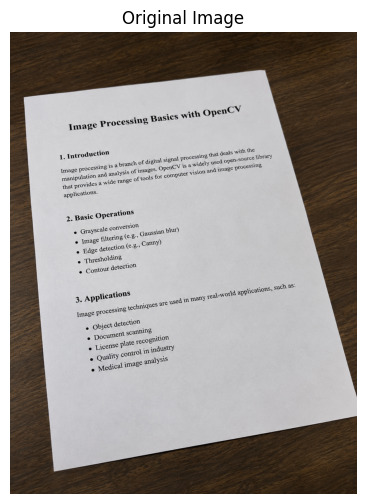

In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))

img = cv2.imread(filename)

if img is None:
    raise ValueError("Image could not be loaded!")

original = img.copy()

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()


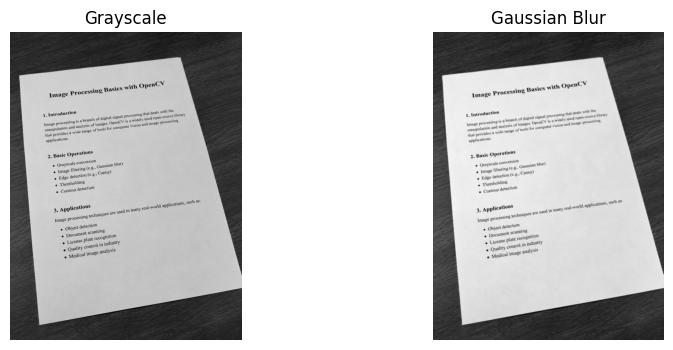

In [3]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(gray, (5, 5), 0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blur, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.show()


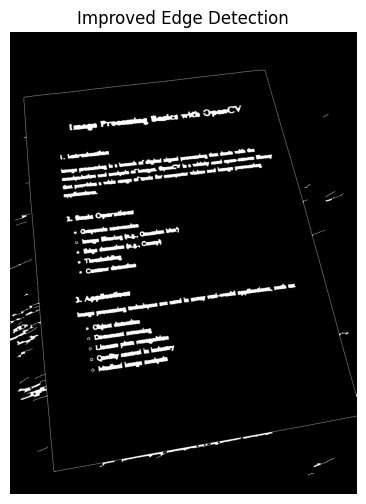

In [8]:
edges = cv2.Canny(blur, 30, 100)


kernel = np.ones((5, 5), np.uint8)

edges = cv2.morphologyEx(
    edges,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(8, 6))
plt.imshow(edges, cmap="gray")
plt.title("Improved Edge Detection")
plt.axis("off")
plt.show()


Document corners detected!


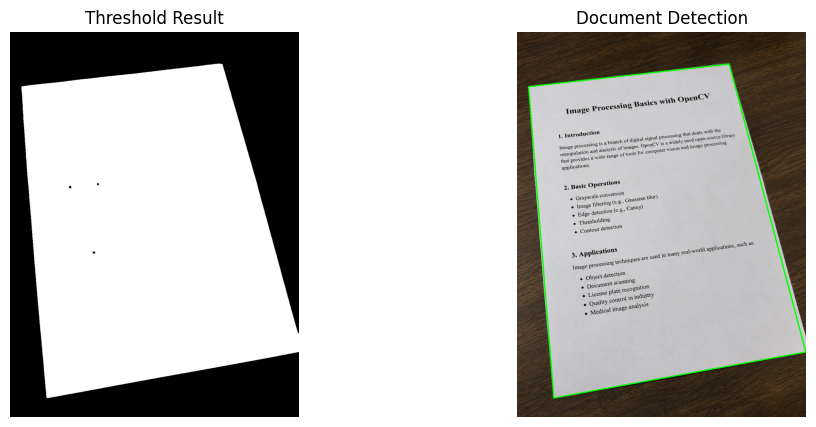

In [11]:

# 1. Convert to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# 2. Apply Gaussian Blur
blur = cv2.GaussianBlur(gray, (7, 7), 0)

# 3. Apply threshold
_, thresh = cv2.threshold(
    blur,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 4. Morphological closing
kernel = np.ones((7, 7), np.uint8)

cleaned = cv2.morphologyEx(
    thresh,
    cv2.MORPH_CLOSE,
    kernel
)

# 5. Find external contours
contours, _ = cv2.findContours(
    cleaned,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# 6. Find the largest contour
document_contour = None

if contours:
    largest = max(contours, key=cv2.contourArea)

    perimeter = cv2.arcLength(largest, True)

    approx = cv2.approxPolyDP(
        largest,
        0.02 * perimeter,
        True
    )

    if len(approx) == 4:
        document_contour = approx

# 7. Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cleaned, cmap="gray")
plt.title("Threshold Result")
plt.axis("off")

plt.subplot(1, 2, 2)

result = original.copy()

if document_contour is not None:
    cv2.drawContours(
        result,
        [document_contour],
        -1,
        (0, 255, 0),
        4
    )
    print("Document corners detected!")
else:
    print("Document not detected!")

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Document Detection")
plt.axis("off")

plt.show()


In [12]:

def order_points(pts):
    pts = pts.reshape(4, 2).astype("float32")

    rect = np.zeros((4, 2), dtype="float32")

    # Sort by vertical position
    y_sorted = pts[np.argsort(pts[:, 1])]

    top = y_sorted[:2]
    bottom = y_sorted[2:]

    rect[0] = top[np.argmin(top[:, 0])]
    rect[1] = top[np.argmax(top[:, 0])]
    rect[2] = bottom[np.argmax(bottom[:, 0])]
    rect[3] = bottom[np.argmin(bottom[:, 0])]

    return rect

pts = order_points(document_contour)
print(pts)


[[  43.  205.]
 [ 797.  120.]
 [1085. 1203.]
 [ 138. 1376.]]


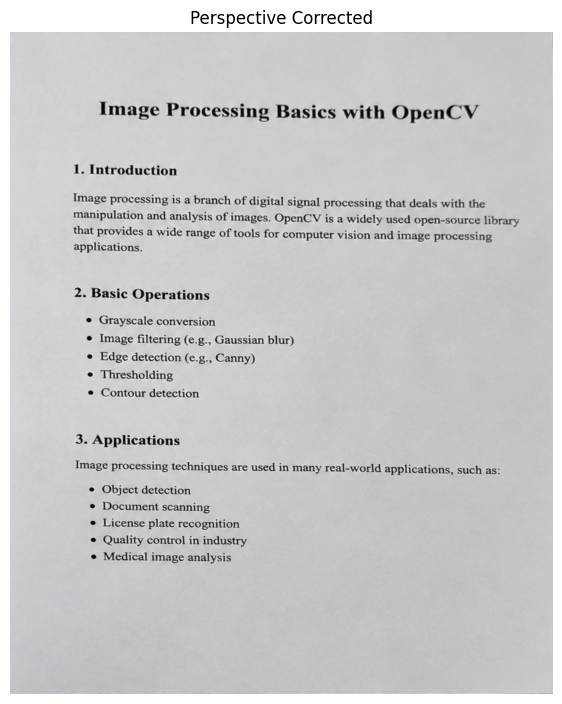

In [13]:

tl, tr, br, bl = pts

widthA = np.linalg.norm(br - bl)
widthB = np.linalg.norm(tr - tl)

heightA = np.linalg.norm(tr - br)
heightB = np.linalg.norm(tl - bl)

maxWidth = int(max(widthA, widthB))
maxHeight = int(max(heightA, heightB))

destination = np.array([
    [0, 0],
    [maxWidth - 1, 0],
    [maxWidth - 1, maxHeight - 1],
    [0, maxHeight - 1]
], dtype="float32")

matrix = cv2.getPerspectiveTransform(
    pts,
    destination
)

warped = cv2.warpPerspective(
    original,
    matrix,
    (maxWidth, maxHeight)
)

plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
plt.title("Perspective Corrected")
plt.axis("off")
plt.show()


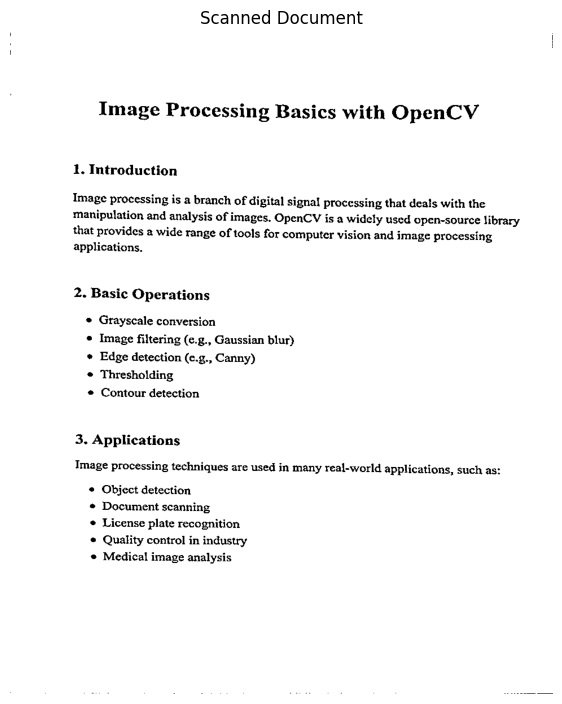

In [14]:

warped_gray = cv2.cvtColor(
    warped,
    cv2.COLOR_BGR2GRAY
)

scanned = cv2.adaptiveThreshold(
    warped_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21,
    10
)

plt.figure(figsize=(7, 9))
plt.imshow(scanned, cmap="gray")
plt.title("Scanned Document")
plt.axis("off")
plt.show()


In [15]:

cv2.imwrite("scanned_document.png", scanned)

cv2.imwrite("perspective_corrected.png", warped)

files.download("scanned_document.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import os, zipfile, cv2
from google.colab import files

os.makedirs("images", exist_ok=True)
os.makedirs("results", exist_ok=True)
cv2.imwrite("images/original_document.jpg", original, [cv2.IMWRITE_JPEG_QUALITY, 95])
cv2.imwrite("results/perspective_corrected.png", warped)
cv2.imwrite("results/scanned_document.png", scanned)

with zipfile.ZipFile("opencv-document-scanner-assets.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for folder in ("images", "results"):
        for name in os.listdir(folder):
            archive.write(os.path.join(folder, name), os.path.join(folder, name))

print("Exported original and processed document images.")
files.download("opencv-document-scanner-assets.zip")

Exported original and processed document images.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>